# CineScore - Modelling, tuning and evaluation
* **Split:** time-ordered 70 / 15 / 15 (train = oldest films, test = newest) - mimics predicting
  films that have not been released yet.
* **Pre-processing:** imputation, one-hot encoding and scaling inside a scikit-learn `Pipeline`
  that is fitted on the training data only.
* **Models:** mean baseline + Ridge regression, KNN, Random Forest, Histogram Gradient Boosting.
* **Tuning:** 5-fold cross-validation (GridSearchCV / RandomizedSearchCV) on the training split.
* **Selection:** best validation MAE. **Test set is used once**, at the end.

All models are scikit-learn only, so the saved pipeline stays small enough for free-tier
deployment (Streamlit Community Cloud, Hugging Face Spaces).

In [1]:
import json
import platform
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, learning_curve
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
RS = 42


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()


df = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet").sort_values("sort_date")
TARGET = "averageRating"
CAT = ["original_language", "us_certification", "main_country"]
DROP = ["tconst", "title", "sort_date", TARGET]
NUM = [c for c in df.columns if c not in DROP + CAT]
print(f"{len(NUM)} numeric/binary + {len(CAT)} categorical = {len(NUM) + len(CAT)} features")

54 numeric/binary + 3 categorical = 57 features


## Time-ordered train / validation / test split (70 / 15 / 15)

In [2]:
n = len(df)
i_tr, i_va = int(0.70 * n), int(0.85 * n)
train, val, test = df.iloc[:i_tr], df.iloc[i_tr:i_va], df.iloc[i_va:]
X_tr, y_tr = train[NUM + CAT], train[TARGET]
X_va, y_va = val[NUM + CAT], val[TARGET]
X_te, y_te = test[NUM + CAT], test[TARGET]
for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} {len(d):6,d} films  {d.sort_date.min():%Y-%m} .. {d.sort_date.max():%Y-%m}"
          f"  mean rating {d[TARGET].mean():.2f}")

train 19,215 films  1979-11 .. 2018-02  mean rating 6.31
val    4,118 films  2018-02 .. 2022-02  mean rating 6.12
test   4,118 films  2022-02 .. 2026-09  mean rating 6.16


## Pre-processing pipeline
* Numeric: median imputation **with missing-value indicators** (budget / track record unknown is
  informative), then standardisation (needed by Ridge and KNN; harmless for trees).
* Categorical: constant "missing" fill, then one-hot encoding; categories with < 30 training
  films are grouped as "infrequent", unseen categories at prediction time are ignored.

In [3]:
def make_preprocessor():
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", StandardScaler())])
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                  min_frequency=30, sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])


def make_pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])


cv = KFold(n_splits=5, shuffle=True, random_state=RS)

## Models and hyper-parameter search (5-fold CV on the training split)

In [4]:
searches = {
    "Baseline (mean)": None,
    "Ridge": GridSearchCV(
        make_pipe(Ridge()), {"model__alpha": [0.1, 1, 10, 30, 100]},
        cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1),
    "KNN": GridSearchCV(
        make_pipe(KNeighborsRegressor()),
        {"model__n_neighbors": [10, 25, 50, 100], "model__weights": ["uniform", "distance"]},
        cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1),
    "Random Forest": RandomizedSearchCV(
        make_pipe(RandomForestRegressor(n_estimators=200, random_state=RS, n_jobs=-1)),
        {"model__max_depth": [10, 15, 20, None], "model__min_samples_leaf": [2, 5, 10],
         "model__max_features": [0.3, 0.5, "sqrt"]},
        n_iter=8, cv=cv, scoring="neg_mean_absolute_error", random_state=RS),
    "Gradient Boosting (HGB)": RandomizedSearchCV(
        make_pipe(HistGradientBoostingRegressor(random_state=RS)),
        {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_iter": [300, 600],
         "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [20, 50],
         "model__l2_regularization": [0.0, 1.0]},
        n_iter=12, cv=cv, scoring="neg_mean_absolute_error", random_state=RS, n_jobs=-1),
}


def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5,
            "R2": r2_score(y, p)}


rows, fitted = [], {}
for name, search in searches.items():
    t0 = time.time()
    if search is None:
        est, cv_mae, params = make_pipe(DummyRegressor()).fit(X_tr, y_tr), np.nan, {}
    else:
        search.fit(X_tr, y_tr)
        est, cv_mae = search.best_estimator_, -search.best_score_
        params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    fitted[name] = est
    tr_m, va_m = metrics(y_tr, est.predict(X_tr)), metrics(y_va, est.predict(X_va))
    rows.append({"model": name, "CV MAE": cv_mae, "train MAE": tr_m["MAE"],
                 "val MAE": va_m["MAE"], "val RMSE": va_m["RMSE"], "val R2": va_m["R2"],
                 "best params": params, "fit time (s)": round(time.time() - t0, 1)})
    print(f"{name:25s} val MAE {va_m['MAE']:.3f}  ({time.time() - t0:.0f}s)  {params}")

results = pd.DataFrame(rows).set_index("model")
results.drop(columns="best params").round(3)

Baseline (mean)           val MAE 0.919  (1s)  {}


Ridge                     val MAE 0.647  (13s)  {'alpha': 30}


KNN                       val MAE 0.666  (21s)  {'n_neighbors': 25, 'weights': 'distance'}


Random Forest             val MAE 0.630  (212s)  {'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None}


Gradient Boosting (HGB)   val MAE 0.623  (122s)  {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 600, 'learning_rate': 0.03, 'l2_regularization': 1.0}


,CV MAE,train MAE,val MAE,val RMSE,val R2,fit time (s)
model,,,,,,
Baseline (mean),NaN,0.847,0.919,1.208,-0.026,0.5
Ridge,0.583,0.579,0.647,0.875,0.461,13.1
KNN,0.608,0.000,0.666,0.918,0.407,21.1
Random Forest,0.561,0.252,0.630,0.866,0.472,212.0
Gradient Boosting (HGB),0.547,0.468,0.623,0.844,0.498,121.7


**Over/under-fitting check:** the gap between train MAE and validation MAE. A large gap means
over-fitting (Random Forest memorises training films); similar, high errors on both mean
under-fitting (baseline, and to some extent Ridge, which cannot model interactions).

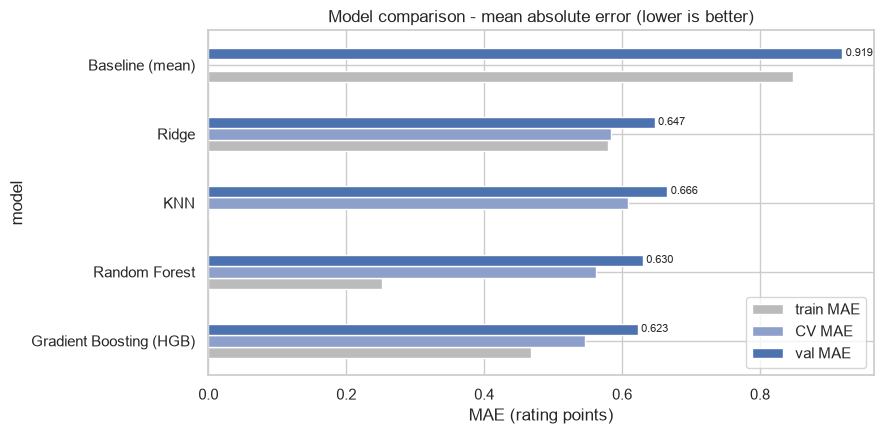

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot = results[["train MAE", "CV MAE", "val MAE"]].iloc[::-1]
plot.plot.barh(ax=ax, color=["#BBBBBB", "#8DA0CB", "#4C72B0"])
for i, v in enumerate(plot["val MAE"]):
    ax.text(v + 0.005, i + 0.17, f"{v:.3f}", va="center", fontsize=8)
ax.set(title="Model comparison - mean absolute error (lower is better)", xlabel="MAE (rating points)")
save("09_model_comparison")

## Final model: refit on train + validation, evaluate ONCE on the test set

In [6]:
best_name = results["val MAE"].idxmin()
print("Selected:", best_name, results.loc[best_name, "best params"])
best_val_model = fitted[best_name]

# prediction interval from validation residuals of the model trained on train only
val_resid = y_va - best_val_model.predict(X_va)
q_lo, q_hi = np.quantile(val_resid, [0.10, 0.90])
print(f"80% interval: prediction {q_lo:+.2f} / {q_hi:+.2f}")

final = make_pipe(clone(best_val_model.named_steps["model"])).fit(
    pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va]))
p_te = final.predict(X_te)
test_metrics = metrics(y_te, p_te)
base_te = metrics(y_te, np.full(len(y_te), pd.concat([y_tr, y_va]).mean()))
coverage = np.mean((y_te >= p_te + q_lo) & (y_te <= p_te + q_hi))
print(f"TEST  {best_name}: MAE {test_metrics['MAE']:.3f}  RMSE {test_metrics['RMSE']:.3f}  "
      f"R2 {test_metrics['R2']:.3f}")
print(f"TEST  baseline : MAE {base_te['MAE']:.3f}  RMSE {base_te['RMSE']:.3f}  R2 {base_te['R2']:.3f}")
print(f"80% interval coverage on test: {coverage:.1%}")

Selected: Gradient Boosting (HGB) {'min_samples_leaf': 50, 'max_leaf_nodes': 63, 'max_iter': 600, 'learning_rate': 0.03, 'l2_regularization': 1.0}


80% interval: prediction -0.98 / +0.95


TEST  Gradient Boosting (HGB): MAE 0.644  RMSE 0.871  R2 0.405
TEST  baseline : MAE 0.886  RMSE 1.136  R2 -0.010
80% interval coverage on test: 78.8%


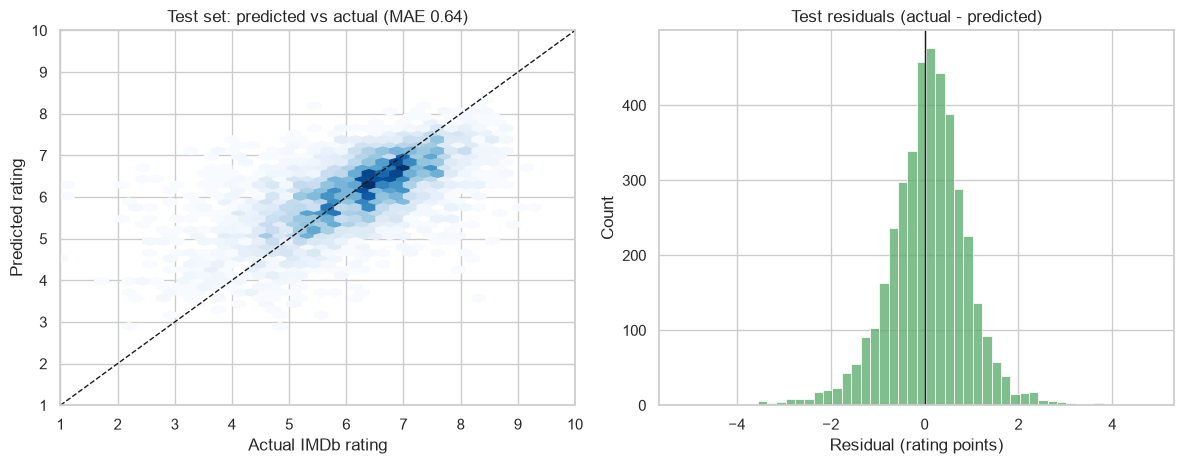

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].hexbin(y_te, p_te, gridsize=35, cmap="Blues", mincnt=1)
axes[0].plot([1, 10], [1, 10], "k--", lw=1)
axes[0].set(xlim=(1, 10), ylim=(1, 10), xlabel="Actual IMDb rating", ylabel="Predicted rating",
            title=f"Test set: predicted vs actual (MAE {test_metrics['MAE']:.2f})")
res = y_te - p_te
sns.histplot(res, bins=50, ax=axes[1], color="#55A868")
axes[1].axvline(0, color="k", lw=1)
axes[1].set(title="Test residuals (actual - predicted)", xlabel="Residual (rating points)")
save("10_test_pred_vs_actual")

### Error analysis: where does the model go wrong?

      films    MAE  mean_bias
band                         
<4      179  1.535      1.520
4-5     462  0.844      0.655
5-6    1083  0.515      0.179
6-7    1511  0.471     -0.214
7-8     758  0.714     -0.672
8+      125  1.410     -1.410

MAE debut directors: 0.768  vs experienced: 0.598


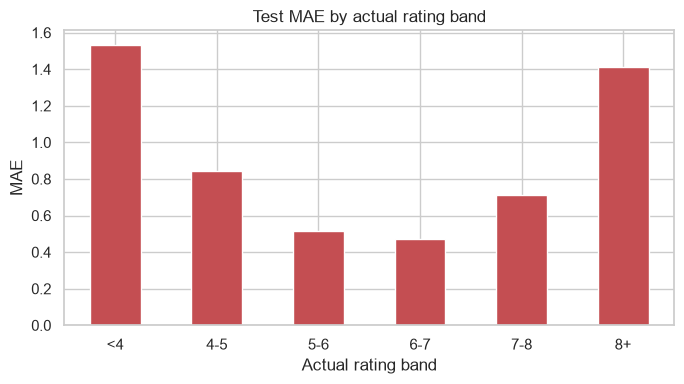

,title,year,averageRating,pred,err
25642,We Love Bad Boys,2024,1.2,6.35,-5.15
27002,Merah Putih: One for All,2025,1.0,6.00,-5.00
25914,Seetha Kalyana Vaibhogame,2024,8.4,3.58,4.82
26573,A Business Proposal,2025,2.0,6.30,-4.30
24834,Adipurush,2023,2.5,6.70,-4.20
25627,Megamind vs. The Doom Syndicate,2024,2.4,6.48,-4.08
23376,Son of India,2022,2.6,6.46,-3.86
25306,Japan,2023,3.2,7.05,-3.85
25729,Bahumukham,2024,8.3,4.55,3.75
27258,Krishna Leela,2025,9.4,5.72,3.68


In [8]:
bands = pd.cut(y_te, [0, 4, 5, 6, 7, 8, 10], labels=["<4", "4-5", "5-6", "6-7", "7-8", "8+"])
by_band = pd.DataFrame({"abs_err": np.abs(res), "bias": -res, "band": bands}) \
    .groupby("band", observed=True).agg(films=("abs_err", "size"), MAE=("abs_err", "mean"),
                                        mean_bias=("bias", "mean")).round(3)
print(by_band)
debut = test.director_prev_count.eq(0)
print(f"\nMAE debut directors: {np.abs(res[debut]).mean():.3f}  "
      f"vs experienced: {np.abs(res[~debut]).mean():.3f}")
fig, ax = plt.subplots(figsize=(7, 4))
by_band.MAE.plot.bar(ax=ax, color="#C44E52")
ax.set(title="Test MAE by actual rating band", xlabel="Actual rating band", ylabel="MAE")
ax.tick_params(axis="x", rotation=0)
save("11_error_by_band")

worst = test.assign(pred=p_te, err=res).reindex(res.abs().sort_values(ascending=False).index)
worst[["title", "year", TARGET, "pred", "err"]].head(10).round(2)

### Which features matter? (permutation importance on the validation set)

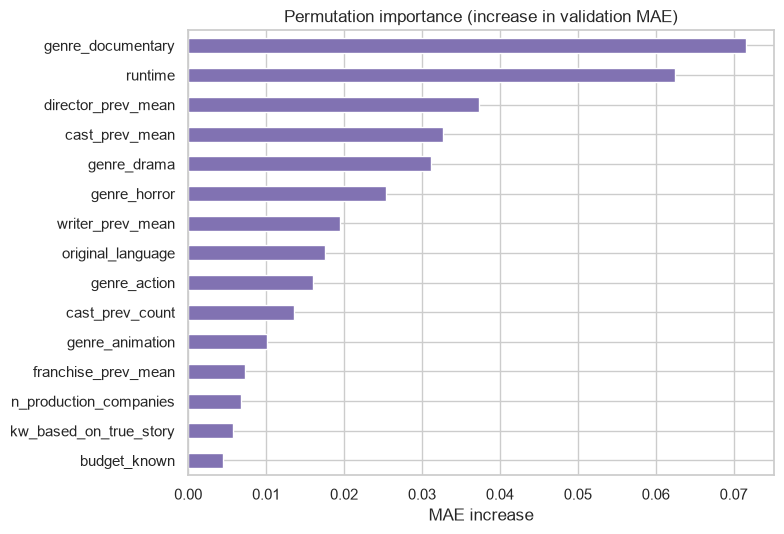

In [9]:
pi = permutation_importance(best_val_model, X_va, y_va, scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=RS, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=NUM + CAT).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5.5))
imp.iloc[::-1].plot.barh(ax=ax, color="#8172B2")
ax.set(title="Permutation importance (increase in validation MAE)", xlabel="MAE increase")
save("12_permutation_importance")

### Learning curve (best model)

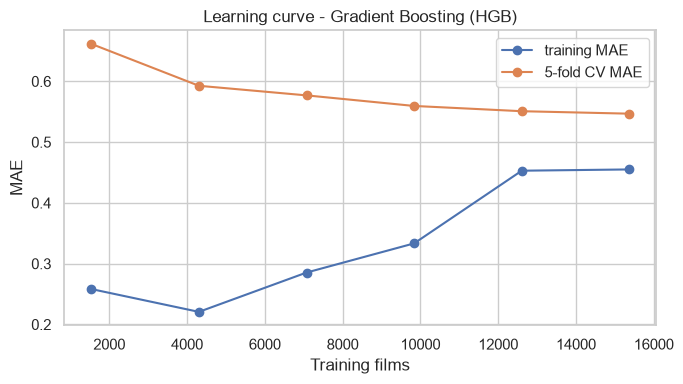

In [10]:
sizes, tr_sc, cv_sc = learning_curve(
    make_pipe(clone(best_val_model.named_steps["model"])), X_tr, y_tr, cv=cv,
    train_sizes=np.linspace(0.1, 1.0, 6), scoring="neg_mean_absolute_error", n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sizes, -tr_sc.mean(1), "o-", label="training MAE")
ax.plot(sizes, -cv_sc.mean(1), "o-", label="5-fold CV MAE")
ax.set(title=f"Learning curve - {best_name}", xlabel="Training films", ylabel="MAE")
ax.legend()
save("13_learning_curve")

## Save the final pipeline

In [11]:
joblib.dump(final, MODELS / "cinescore_pipeline.joblib", compress=3)
meta = {
    "model": best_name,
    "best_params": {k: (v if isinstance(v, (int, float, str)) or v is None else str(v))
                    for k, v in results.loc[best_name, "best params"].items()},
    "features_numeric": NUM, "features_categorical": CAT,
    "interval_80": [float(q_lo), float(q_hi)],
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "baseline_test_metrics": {k: round(float(v), 4) for k, v in base_te.items()},
    "test_interval_coverage": round(float(coverage), 4),
    "validation_table": results.drop(columns="best params").round(4).reset_index()
                               .to_dict(orient="records"),
    "train_rows": len(X_tr) + len(X_va), "test_rows": len(X_te),
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
(MODELS / "metadata.json").write_text(json.dumps(meta, indent=2, default=str))
size_mb = (MODELS / "cinescore_pipeline.joblib").stat().st_size / 1e6
print(f"saved pipeline ({size_mb:.1f} MB) + metadata.json")

# sanity: reload and predict
reloaded = joblib.load(MODELS / "cinescore_pipeline.joblib")
assert np.allclose(reloaded.predict(X_te.head()), p_te[:5])

saved pipeline (1.1 MB) + metadata.json
